SENTIMENT ANALYSIS BY MOHAMMED INABAH KHAN

1. INSTALLING THE REQUIRED LIBRARIES

In [1]:
%pip install -q "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn nltk wordcloud

2. IMPORTS AND LOADING THE DATASET FROM KAGGLE

In [14]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from kagglehub import KaggleDatasetAdapter

DATASET = "jp797498e/twitter-entity-sentiment-analysis"

columns = ["id", "entity", "sentiment", "tweet"]

# Load the labeled training file directly from Kaggle
df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    DATASET,
    "twitter_training.csv",
    pandas_kwargs={
        "header": None,
        "names": columns
    }
)

print("First 5 records:")
display(df.head())

validation_df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    DATASET,
    "twitter_validation.csv",
    pandas_kwargs={
        "header": None,
        "names": columns
    }
)

print("Training shape:", df.shape)
print("Validation shape:", validation_df.shape)

Using Colab cache for faster access to the 'twitter-entity-sentiment-analysis' dataset.
First 5 records:


,id,entity,sentiment,tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


100%|██████████| 160k/160k [00:00<00:00, 1.74MB/s]

Training shape: (74682, 4)
Validation shape: (1000, 4)


3. INITIAL INSPECTION

In [15]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSentiment labels:")
print(df["sentiment"].value_counts(dropna=False))

print("\nUnique sentiment categories:")
print(df["sentiment"].dropna().unique())

Dataset shape: (74682, 4)

Column names:
['id', 'entity', 'sentiment', 'tweet']

Data types:
id            int64
entity       object
sentiment    object
tweet        object
dtype: object

Missing values per column:
id             0
entity         0
sentiment      0
tweet        686
dtype: int64

Duplicate rows: 2700

Sentiment labels:
sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64

Unique sentiment categories:
['Positive' 'Neutral' 'Negative' 'Irrelevant']


4. CLEANING THE DATA AND INSPECTING SENTIMENT CLASSES

In [16]:
# Work on a copy
df = df.copy()

# Normalize label formatting
df["sentiment"] = (
    df["sentiment"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Remove rows without usable text or sentiment
df = df.dropna(subset=["tweet", "sentiment"])
df["tweet"] = df["tweet"].astype(str).str.strip()
df = df[df["tweet"].ne("")]

# Remove exact duplicate records
df = df.drop_duplicates()

# Keep the three classes required by the internship
target_classes = ["Positive", "Negative", "Neutral"]
df = df[df["sentiment"].isin(target_classes)].copy()

print("Cleaned dataset shape:", df.shape)
print("\nFinal class counts:")
print(df["sentiment"].value_counts())

print("\nMissing values after cleaning:")
print(df[["tweet", "sentiment"]].isnull().sum())

Cleaned dataset shape: (58669, 4)

Final class counts:
sentiment
Negative    21571
Positive    19557
Neutral     17541
Name: count, dtype: Int64

Missing values after cleaning:
tweet        0
sentiment    0
dtype: int64


5. VISUALISING THE SENTIMENT DISTRIBUTION

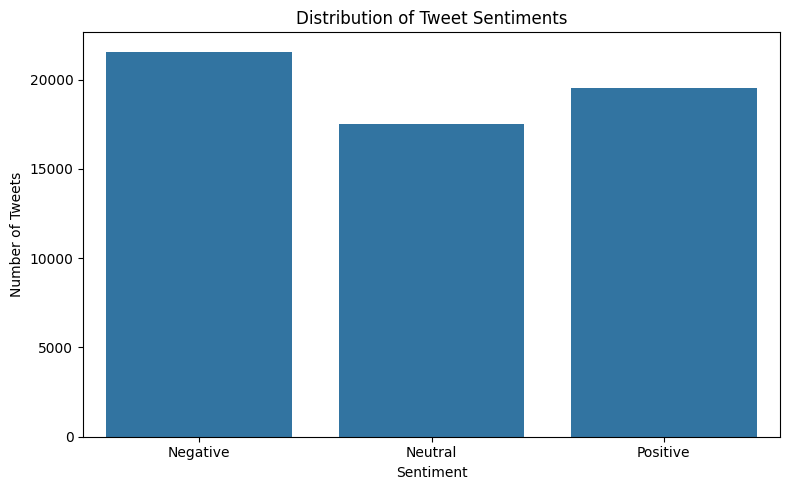

Sentiment percentages:


,Percentage
sentiment,
Negative,36.77
Neutral,29.9
Positive,33.33


In [17]:
sentiment_order = ["Negative", "Neutral", "Positive"]

counts = df["sentiment"].value_counts().reindex(
    sentiment_order, fill_value=0
)

plt.figure(figsize=(8, 5))
sns.barplot(x=counts.index, y=counts.values)
plt.title("Distribution of Tweet Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.tight_layout()
plt.show()

print("Sentiment percentages:")
display((counts / counts.sum() * 100).round(2).rename("Percentage"))

6. TEXT PREPROCESSING

In [18]:
import re
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("english"))

# Preserve words that can reverse sentiment
stop_words -= {"no", "nor", "not"}

def preprocess_text(text):
    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove user mentions
    text = re.sub(r"@\w+", " ", text)

    # Remove punctuation and non-letter characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Tokenization
    tokens = text.split()

    # Stopword removal
    tokens = [word for word in tokens if word not in stop_words]

    return " ".join(tokens)

df["clean_tweet"] = df["tweet"].apply(preprocess_text)

# Remove records that become empty after preprocessing
df = df[df["clean_tweet"].str.strip().ne("")].copy()

display(df[["tweet", "clean_tweet", "sentiment"]].head(10))

,tweet,clean_tweet,sentiment
0,im getting on borderlands and i will murder yo...,im getting borderlands murder,Positive
1,I am coming to the borders and I will kill you...,coming borders kill,Positive
2,im getting on borderlands and i will kill you ...,im getting borderlands kill,Positive
3,im coming on borderlands and i will murder you...,im coming borderlands murder,Positive
4,im getting on borderlands 2 and i will murder ...,im getting borderlands murder,Positive
5,im getting into borderlands and i can murder y...,im getting borderlands murder,Positive
6,So I spent a few hours making something for fu...,spent hours making something fun know huge fan...,Positive
7,So I spent a couple of hours doing something f...,spent couple hours something fun know huge bor...,Positive
8,So I spent a few hours doing something for fun...,spent hours something fun know huge borderland...,Positive
9,So I spent a few hours making something for fu...,spent hours making something fun know huge rha...,Positive


7. CREATING WORDCLOUDS FOR ALL THREE SENTIMENTS

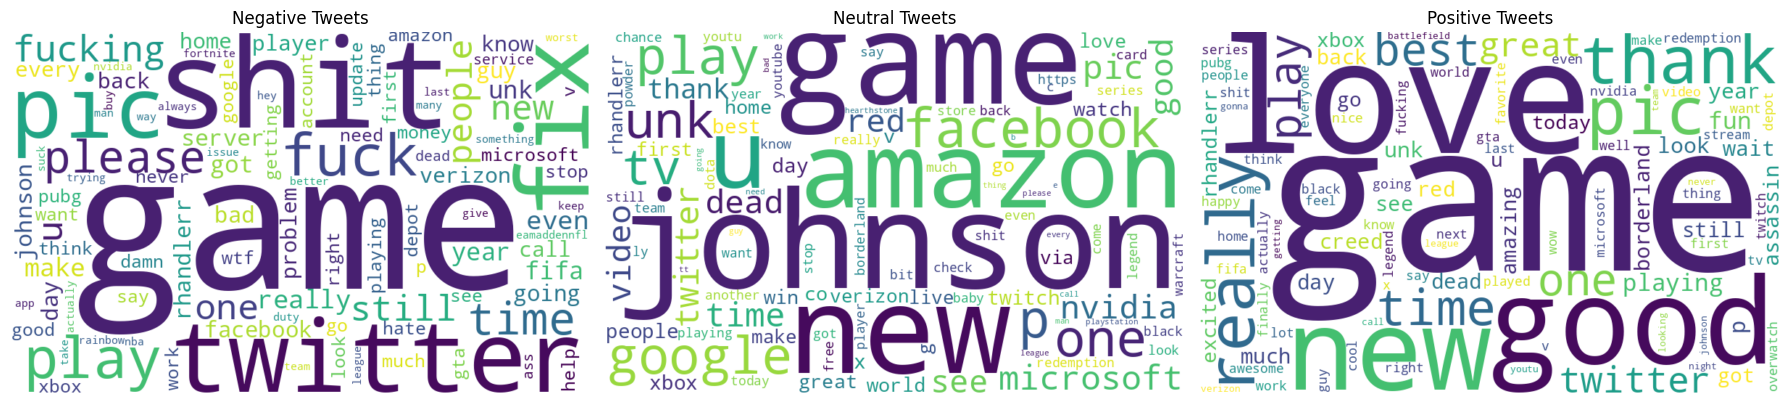

In [19]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, sentiment in zip(axes, sentiment_order):
    text_data = " ".join(
        df.loc[df["sentiment"] == sentiment, "clean_tweet"]
    )

    if text_data.strip():
        cloud = WordCloud(
            width=800,
            height=500,
            background_color="white",
            max_words=100,
            collocations=False,
            random_state=42
        ).generate(text_data)

        ax.imshow(cloud, interpolation="bilinear")
        ax.set_title(f"{sentiment} Tweets")
    else:
        ax.set_title(f"{sentiment}: no usable text")

    ax.axis("off")

plt.tight_layout()
plt.show()

8. SPLITTING THE DATASET INTO TRAINING AND TESTING SETS

In [20]:
from sklearn.model_selection import train_test_split

X = df["clean_tweet"]
y = df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("\nTraining proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training records: 45961
Testing records: 11491

Training proportions:
sentiment
Negative    0.369
Positive    0.333
Neutral     0.299
Name: proportion, dtype: Float64

Testing proportions:
sentiment
Negative    0.369
Positive    0.333
Neutral     0.299
Name: proportion, dtype: Float64


9. FEATURE EXTRACTION AND TRAINING NAIVE BAYES & LOGISTIC REGRESSION

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

models = {
    "Naive Bayes": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", MultinomialNB())
    ]),

    "Logistic Regression": Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=50000,
            ngram_range=(1, 2),
            min_df=2,
            sublinear_tf=True
        )),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ])
}

predictions = {}
fitted_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)

    fitted_models[name] = model
    predictions[name] = model.predict(X_test)

    print(f"{name} training complete.")

print("\nAll models trained.")

Training Naive Bayes...
Naive Bayes training complete.
Training Logistic Regression...
Logistic Regression training complete.

All models trained.


10. EVALUATING BOTH MODELS


Classification Report: Naive Bayes
              precision    recall  f1-score   support

    Negative       0.82      0.92      0.87      4238
     Neutral       0.90      0.71      0.80      3432
    Positive       0.83      0.87      0.85      3821

    accuracy                           0.84     11491
   macro avg       0.85      0.83      0.84     11491
weighted avg       0.85      0.84      0.84     11491



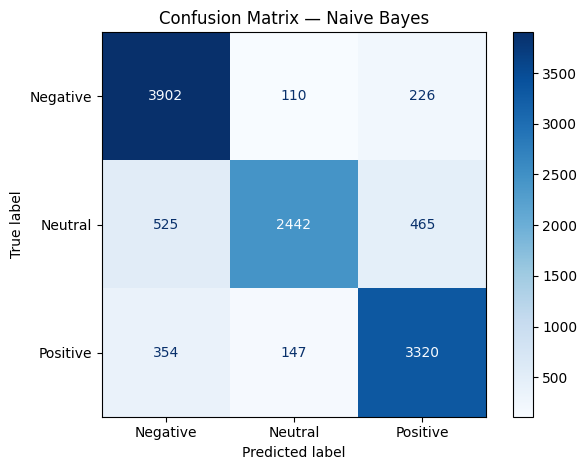


Classification Report: Logistic Regression
              precision    recall  f1-score   support

    Negative       0.86      0.92      0.89      4238
     Neutral       0.90      0.80      0.85      3432
    Positive       0.86      0.88      0.87      3821

    accuracy                           0.87     11491
   macro avg       0.87      0.87      0.87     11491
weighted avg       0.87      0.87      0.87     11491



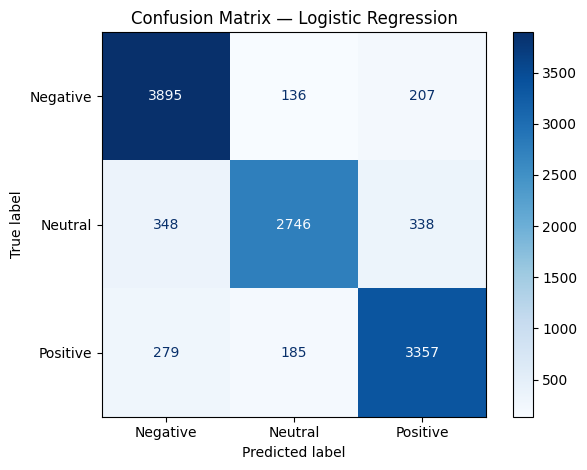


Model comparison:


,Accuracy,Precision (weighted),Recall (weighted),F1-score (weighted)
Model,,,,
Naive Bayes,0.8410,0.8465,0.8410,0.8390
Logistic Regression,0.8701,0.8712,0.8701,0.8694


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (weighted)": precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "Recall (weighted)": recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        ),
        "F1-score (weighted)": f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
    })

    print(f"\n{'=' * 55}")
    print(f"Classification Report: {name}")
    print(classification_report(
        y_test,
        y_pred,
        labels=sentiment_order,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_test, y_pred, labels=sentiment_order
    )

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=sentiment_order
    )

    display_cm.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix — {name}")
    plt.tight_layout()
    plt.show()

results_df = pd.DataFrame(results).set_index("Model")

print("\nModel comparison:")
display(results_df.round(4))

11. PLOTTING THE MODEL COMPARISONS

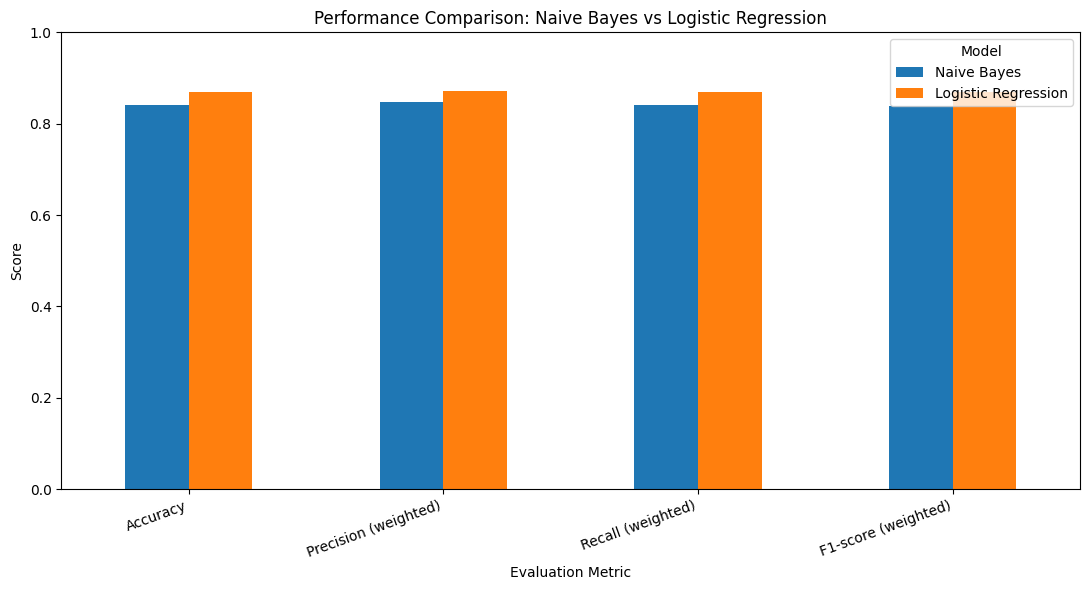

In [23]:
metrics_to_plot = [
    "Accuracy",
    "Precision (weighted)",
    "Recall (weighted)",
    "F1-score (weighted)"
]

results_df[metrics_to_plot].T.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Performance Comparison: Naive Bayes vs Logistic Regression")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Model")
plt.tight_layout()
plt.show()

12, ERROR ANALYSIS

In [24]:
best_model_name = results_df["F1-score (weighted)"].idxmax()

best_predictions = predictions[best_model_name]

errors = pd.DataFrame({
    "Original Tweet": df.loc[X_test.index, "tweet"],
    "Cleaned Tweet": X_test,
    "Actual Sentiment": y_test,
    "Predicted Sentiment": best_predictions
}, index=X_test.index)

errors = errors[
    errors["Actual Sentiment"] != errors["Predicted Sentiment"]
]

print("Selected model:", best_model_name)
print("Total misclassified examples:", len(errors))

display(errors.head(5))

Selected model: Logistic Regression
Total misclassified examples: 1493


,Original Tweet,Cleaned Tweet,Actual Sentiment,Predicted Sentiment
52526,Now that I've seen the (fake) rumors that Bull...,seen fake rumors bully happening want ever eve...,Neutral,Negative
69561,GOD JUST SET ME CUSTOMIZE MY MASSIVE COCK SMH,god set customize massive cock smh,Neutral,Negative
60809,Is it really worth getting Grand Theft Auto V ...,really worth getting grand theft auto v video ...,Neutral,Negative
2795,<unk>! More recycled content! Like getting I e...,unk recycled content like getting excited like...,Negative,Positive
61317,Hollywood fucking hills bruh... only CJ from G...,hollywood fucking hills bruh cj gta damn andre...,Neutral,Negative


# Conclusion — Twitter Sentiment Analysis

This project applied natural language processing and machine learning techniques to classify tweets into positive, negative, and neutral sentiment categories. The Twitter Entity Sentiment Analysis dataset was obtained directly from Kaggle and prepared by removing unusable text records, normalizing sentiment labels, and excluding the irrelevant class to match the three-class objective.

Text preprocessing included lowercasing, URL and mention removal, punctuation removal, tokenization, and stopword removal while preserving important negation words. TF-IDF was used to convert the cleaned text into numerical features.

Two classifiers, Multinomial Naive Bayes and Logistic Regression, were trained using an 80/20 stratified train/test split. Their performance was compared using accuracy, precision, recall, F1-score, classification reports, and confusion matrices.

**Model comparison:** [Insert the observed results for both models and identify the stronger model based on the selected evaluation metrics.]

The sentiment distribution chart and WordClouds provided an overview of the dataset's class balance and common words within each sentiment category. Error analysis of five misclassified tweets highlighted potential challenges involving ambiguous language, sarcasm, slang, and context-dependent expressions.

A practical application of this project is monitoring customer opinions about products, brands, or services on social media. Organizations could use sentiment classification to identify emerging dissatisfaction and prioritize feedback for further investigation.

However, the model's predictions should not be treated as perfect measures of public opinion. Performance can be affected by class imbalance, noisy text, ambiguous sentiment, and changes in language over time. Further improvements could include better handling of emojis and slang, hyperparameter tuning, and evaluation on a separate dataset from a different period or source.